---
title: "1.7 Perfil de riesgos de Leticia: lo que dicen los datos"
short_title: "1.7 Perfil de riesgos (cuaderno)"
subtitle: "Eventos históricos, tamizaje global y señales climáticas para priorizar amenazas"
description: "Cuaderno que reúne DesInventar, la UNGRD, ThinkHazard, el IDEAM, ERA5 y el CCKP para priorizar las amenazas analizadas en la Sección 3."
keywords: [perfil de riesgo, DesInventar, UNGRD, ThinkHazard, priorización, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/01_conceptos/17_perfil_riesgos.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

La [revisión de evidencia](16_evidencia.md) resume lo que dicen la OTCA, el Panel Científico por la Amazonía, el
IDEAM y la literatura. Este cuaderno pone a prueba esa revisión con **datos abiertos**: qué desastres se han
registrado en Leticia, qué nivel de amenaza asigna el tamizaje global del Banco Mundial, qué muestran las series
del río y del clima y qué proyectan los modelos. El resultado es la **matriz de priorización** que define los seis
flujos de la Sección 3.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import fuentes, hidro, indicadores, viz

## 1. Desastres registrados, 1970–2025

In [3]:
ev = indicadores.tabla_eventos()
ev["decada"] = (ev.index.year // 10) * 10
conteo = ev.pivot_table(index="categoria", columns="decada", values="evento", aggfunc="count", fill_value=0)
conteo.columns = [f"{c}s" for c in conteo.columns]
conteo["total"] = conteo.sum(axis=1)
afect = ev.groupby("categoria")[["afectados", "viviendas_averiadas", "viviendas_destruidas"]].sum()
resumen = conteo.join(afect).sort_values("total", ascending=False)
display(resumen.round(0))

,1970s,1980s,1990s,2000s,2010s,2020s,total,afectados,viviendas_averiadas,viviendas_destruidas
categoria,,,,,,,,,,
Inundación,4,3,8,8,6,4,33,"65,577.00","5,214.00",440.00
Incendio estructural,2,0,2,1,9,7,21,71.00,6.00,35.00
Incendio de cobertura vegetal,0,0,0,0,4,14,18,0.00,0.00,1.00
Vendaval y lluvias,0,0,2,0,4,4,10,832.00,259.00,5.00
Accidentes de transporte,0,0,0,0,3,3,6,77.00,0.00,0.00
Erosión y movimientos en masa,0,0,0,2,3,1,6,"4,300.00",43.00,8.00
Otros,1,0,1,0,1,0,3,72.00,0.00,0.00
Sequía y desabastecimiento,0,1,1,0,0,0,2,"5,000.00",0.00,0.00


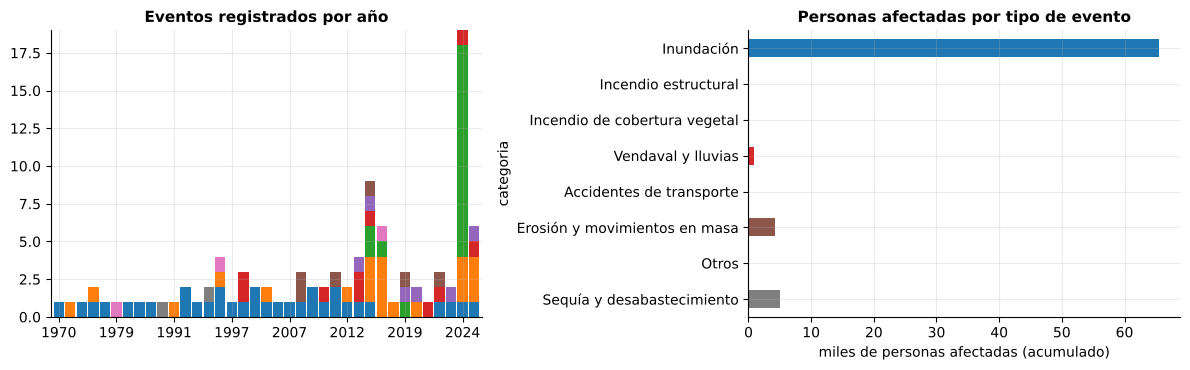

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
orden = resumen.index
colores = plt.get_cmap("tab10").colors
ev_anual = ev.pivot_table(index=ev.index.year, columns="categoria", values="evento", aggfunc="count", fill_value=0)
ev_anual.reindex(columns=orden).plot.bar(stacked=True, ax=ax[0], width=0.9, color=colores[:len(orden)], legend=False)
ax[0].set_xticks(range(0, len(ev_anual), 5))
ax[0].set_xticklabels(ev_anual.index[::5], rotation=0)
ax[0].set_title("Eventos registrados por año")
ax[0].set_xlabel("")
(resumen["afectados"] / 1000).plot.barh(ax=ax[1], color=[colores[list(orden).index(i)] for i in resumen.index])
ax[1].invert_yaxis()
ax[1].set_xlabel("miles de personas afectadas (acumulado)")
ax[1].set_title("Personas afectadas por tipo de evento")
fig.tight_layout()

In [5]:
viz.pie(viz.nota_fuente("desinventar", "emergencias_ungrd"))

*Fuente: DesInventar Sendai (Corporación OSSO / UNDRR) con registros de la UNGRD — Exportación nacional de Colombia (fichas por municipio); UNGRD — Consolidado de emergencias por municipio (Datos Abiertos Colombia).*

**Lectura.** Las **inundaciones** dominan el registro histórico por número de eventos y, de lejos, por personas
afectadas: el PIGCCT de Amazonas reporta para 1990–2015 más de cien mil afectados acumulados por inundaciones en el
departamento, sobre todo en Leticia y Puerto Nariño [@pigcct2022amazonas]. Desde 2019 el registro de la UNGRD
muestra un perfil distinto: **incendios de cobertura vegetal** (14 en 2024), **vendavales** casi todos los años y
**erosión**. La sequía casi no aparece como «evento», porque sus impactos (aislamiento, desabastecimiento) se
registran poco: es un riesgo **subregistrado**.

## 2. El tamizaje global del Banco Mundial (ThinkHazard)

In [6]:
th = fuentes.thinkhazard()
NOMBRES = {"River flood": "Inundación fluvial", "Urban flood": "Inundación urbana", "Coastal flood": "Inundación costera",
           "Earthquake": "Sismo", "Landslide": "Deslizamiento", "Tsunami": "Tsunami", "Volcano": "Volcán", "Cyclone": "Ciclón",
           "Water scarcity": "Escasez de agua", "Extreme heat": "Calor extremo", "Wildfire": "Incendio forestal"}
NIVELES = {"High": "Alta", "Medium": "Media", "Low": "Baja", "Very low": "Muy baja", "No Data": "Sin datos"}
th = th.assign(amenaza=th["amenaza"].map(NOMBRES), nivel=th["nivel"].map(NIVELES)).set_index("amenaza")[["nivel"]]
display(th)

,nivel
amenaza,
Inundación fluvial,Alta
Inundación urbana,Alta
Inundación costera,Sin datos
Sismo,Muy baja
Deslizamiento,Muy baja
Tsunami,Sin datos
Volcán,Sin datos
Ciclón,Sin datos
Escasez de agua,Muy baja


In [7]:
viz.pie(viz.nota_fuente("thinkhazard"))

*Fuente: GFDRR – Banco Mundial — ThinkHazard! (Leticia, código 13336).*

ThinkHazard confirma la **inundación fluvial y urbana** como amenazas altas y el **calor** como media. Califica la
escasez de agua como muy baja porque mide la disponibilidad media de agua, no el aislamiento por estiaje del río
ni la dependencia de la ciudad del transporte fluvial: ahí la evidencia local corrige al tamizaje global.

## 3. Señales en las series del río y del clima

In [8]:
nivel = hidro.limpiar_nivel(fuentes.nivel_rio())
mx, mn = hidro.extremos_anuales(nivel, "max")["valor"], hidro.extremos_anuales(nivel, "min")["valor"]
era = fuentes.clima_diario()
tmax = era["temperature_2m_max"]
tmax_a = tmax[tmax.index.year < pd.Timestamp.today().year].groupby(tmax.index.year[tmax.index.year < pd.Timestamp.today().year]).mean()
mk_t = hidro.mann_kendall(tmax_a.loc[1980:])
deltas = fuentes.cckp_tabla(["tasmax", "pr", "rx1day", "spei12"], escenarios=["ssp245"], periodos=["2040-2059"], percentiles=["median"])
d = deltas.set_index("variable")["valor"]
senales = pd.DataFrame([
    ["Creciente máxima registrada", f"{mx.max()/100:.2f} m ({mx.idxmax()})", "IDEAM, regla de Leticia"],
    ["Vaciante mínima registrada", f"{mn.min()/100:.2f} m ({mn.idxmin()})", "IDEAM, regla de Leticia"],
    ["Tendencia de la temperatura máxima 1980–hoy", f"{mk_t['sen']*10:+.2f} °C/década (p = {mk_t['p']:.3f})", "ERA5"],
    ["Cambio de Tmax a 2040–2059 (SSP2-4.5)", f"{d['tasmax']:+.1f} °C", "CCKP, CMIP6"],
    ["Cambio de lluvia anual a 2040–2059 (SSP2-4.5)", f"{d['pr']:+.0f} mm", "CCKP, CMIP6"],
    ["Cambio de lluvia máxima diaria a 2040–2059 (SSP2-4.5)", f"{d['rx1day']:+.1f} mm", "CCKP, CMIP6"],
    ["Cambio del SPEI-12 a 2040–2059 (SSP2-4.5)", f"{d['spei12']:+.2f}", "CCKP, CMIP6"],
], columns=["indicador", "valor", "fuente"]).set_index("indicador")
display(senales)

,valor,fuente
indicador,,
Creciente máxima registrada,18.52 m (2015),"IDEAM, regla de Leticia"
Vaciante mínima registrada,2.24 m (2024),"IDEAM, regla de Leticia"
Tendencia de la temperatura máxima 1980–hoy,+0.22 °C/década (p = 0.000),ERA5
Cambio de Tmax a 2040–2059 (SSP2-4.5),+1.2 °C,"CCKP, CMIP6"
Cambio de lluvia anual a 2040–2059 (SSP2-4.5),-70 mm,"CCKP, CMIP6"
Cambio de lluvia máxima diaria a 2040–2059 (SSP2-4.5),+2.8 mm,"CCKP, CMIP6"
Cambio del SPEI-12 a 2040–2059 (SSP2-4.5),-0.62,"CCKP, CMIP6"


## 4. Matriz de priorización

,puntaje,prioridad
Sequía y estiaje,14,alta
Inundación fluvial,13,alta
Lluvias intensas y vendavales,12,alta
Erosión y dinámica fluvial,11,media
Calor extremo,11,media
Incendios y humo,11,media
Movimientos en masa,6,baja
Sismo,5,baja


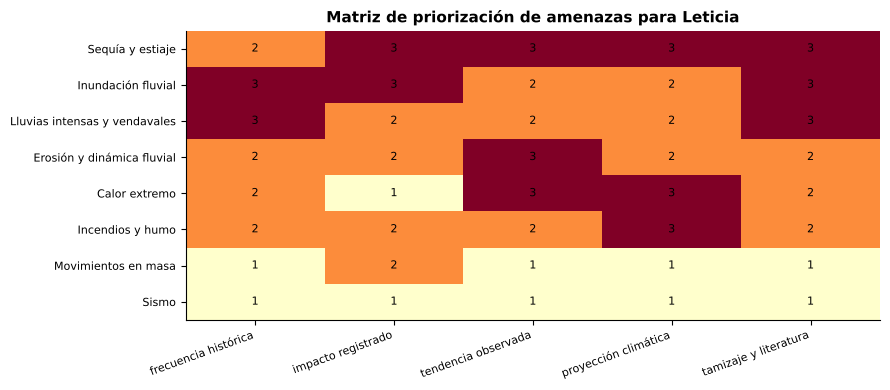

In [9]:
# Puntajes 1 (bajo) – 3 (alto). Frecuencia e impacto salen de los registros; tendencia, proyección y evidencia
# de las secciones 1.6 y 3.x. Se documentan aquí para que cualquiera pueda cambiarlos y recalcular.
matriz = pd.DataFrame({
    "frecuencia histórica":  {"Inundación fluvial": 3, "Sequía y estiaje": 2, "Erosión y dinámica fluvial": 2, "Calor extremo": 2,
                              "Incendios y humo": 2, "Lluvias intensas y vendavales": 3, "Sismo": 1, "Movimientos en masa": 1},
    "impacto registrado":    {"Inundación fluvial": 3, "Sequía y estiaje": 3, "Erosión y dinámica fluvial": 2, "Calor extremo": 1,
                              "Incendios y humo": 2, "Lluvias intensas y vendavales": 2, "Sismo": 1, "Movimientos en masa": 2},
    "tendencia observada":   {"Inundación fluvial": 2, "Sequía y estiaje": 3, "Erosión y dinámica fluvial": 3, "Calor extremo": 3,
                              "Incendios y humo": 2, "Lluvias intensas y vendavales": 2, "Sismo": 1, "Movimientos en masa": 1},
    "proyección climática":  {"Inundación fluvial": 2, "Sequía y estiaje": 3, "Erosión y dinámica fluvial": 2, "Calor extremo": 3,
                              "Incendios y humo": 3, "Lluvias intensas y vendavales": 2, "Sismo": 1, "Movimientos en masa": 1},
    "tamizaje y literatura": {"Inundación fluvial": 3, "Sequía y estiaje": 3, "Erosión y dinámica fluvial": 2, "Calor extremo": 2,
                              "Incendios y humo": 2, "Lluvias intensas y vendavales": 3, "Sismo": 1, "Movimientos en masa": 1},
})
matriz["puntaje"] = matriz.sum(axis=1)
matriz = matriz.sort_values("puntaje", ascending=False)
matriz["prioridad"] = pd.cut(matriz["puntaje"], [0, 8, 11, 15], labels=["baja", "media", "alta"])
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(matriz.iloc[:, :5].values, cmap="YlOrRd", vmin=1, vmax=3, aspect="auto")
ax.set_xticks(range(5)); ax.set_xticklabels(matriz.columns[:5], rotation=20, ha="right", fontsize=8)
ax.set_yticks(range(len(matriz))); ax.set_yticklabels(matriz.index, fontsize=8)
for i in range(len(matriz)):
    for j in range(5):
        ax.text(j, i, matriz.iloc[i, j], ha="center", va="center", fontsize=8)
ax.grid(False)
ax.set_title("Matriz de priorización de amenazas para Leticia")
fig.tight_layout()
display(matriz[["puntaje", "prioridad"]])

**Resultado.** Seis amenazas obtienen prioridad media o alta y se analizan en la Sección 3, en este orden:
[3.1 inundación fluvial](../03_analisis/31_inundacion/index.md), [3.2 sequía y estiaje](../03_analisis/32_sequia/index.md),
[3.3 erosión y dinámica fluvial](../03_analisis/33_erosion/index.md), [3.4 calor extremo](../03_analisis/34_calor/index.md),
[3.5 incendios y humo](../03_analisis/35_incendios/index.md) y [3.6 lluvias intensas y vendavales](../03_analisis/36_lluvias_vendavales/index.md).
El sismo (zona de amenaza sísmica baja según la NSR-10) y los movimientos en masa (relieve plano; eventos
puntuales en taludes y barrancos, que se tratan con la erosión) quedan fuera del análisis detallado.